In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pandas.api.types import is_numeric_dtype

import pinner2026_jpo_code
import pinner2026_jpo_code.IO

In [ ]:
RAW_DATA_DIR: Path = pinner2026_jpo_code.DATA_DIR / "raw"
INTERIM_DATA_DIR: Path = pinner2026_jpo_code.DATA_DIR / "interim"

In [3]:
def clean_csv(df):
    if "Unnamed: 0" in df.columns:
        df.set_index(pd.to_datetime(df["Unnamed: 0"]), inplace=True)
        df.drop("Unnamed: 0", inplace=True, axis="columns")
    # Convert back to complex numbers
    # https://stackoverflow.com/questions/18919699/python-pandas-complex-number
    for i, col in enumerate(df.columns):
        if not is_numeric_dtype(df[col]):
            df[col] = df[col].str.replace("i", "j").apply(lambda x: complex(x))
    df = df.fillna(0)

    if df.index.diff().mean() < pd.Timedelta(days=5):
        origin = pd.to_datetime("2017-01-03")
        df = df.resample("5D", origin=origin).mean()
        df = df.loc[origin:]

    # if df.index.iloc[-1] > pd
    return df


def setup_two_subplots(figsize):
    fig = plt.figure(figsize=figsize)  # Adjust figure size as needed
    gs = fig.add_gridspec(1, 2, width_ratios=[3, 1])  # 3:1 width ratio

    # Create the Cartesian subplot (left)
    ax1 = fig.add_subplot(gs[0, 0])
    # Create the Polar subplot (right)
    ax2 = fig.add_subplot(gs[0, 1], projection="polar")

    return fig, [ax1, ax2]


def cart2pol(x, y):
    rho = np.sqrt(x**2 + y**2)
    phi = np.arctan2(y, x)
    return (rho, phi)


colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2"]


def plot_complex_df(df, axes, color_list, title=None):

    try:
        if len(axes) == 2:
            axis = axes[0]
        else:
            raise NotImplementedError

        for col in df.columns:
            radius, angle = cart2pol(np.real(df[col]), np.imag(df[col]))
            axes[1].scatter(angle, radius, c=df.index, cmap="Grays")

    except TypeError:
        axis = axes

    cycler = (color for color in color_list)
    for col in df.columns:
        color = next(cycler)
        axis.plot(df.index, np.real(df[col]), color=color, label=col)
        if not np.all(np.imag(df[col]) == 0):
            axis.plot(df.index, np.imag(df[col]), ls="--", color=color)
        if title:
            axis.set_title(title)
        axis.axhline(0, color="k", alpha=0.1, ls=":")
        axis.xaxis.set_major_formatter(mdates.ConciseDateFormatter(axis.xaxis.get_major_locator()))
        axis.legend()

In [4]:
sea_ice_concentrations = pd.read_csv(folder + "daily_sea_ice_concentrations.csv")
sea_ice_concentrations = clean_csv(sea_ice_concentrations)
sea_ice_concentrations = sea_ice_concentrations
sea_ice_concentrations.head()

,A,B,C,D,E,F,G
Unnamed: 0,,,,,,,
2017-01-03,0.000196,0.005714,0.0,0.0,0.0,0.0,0.0
2017-01-08,0.000000,0.006295,0.0,0.0,0.0,0.0,0.0
2017-01-13,0.000000,0.005437,0.0,0.0,0.0,0.0,0.0
2017-01-18,0.000045,0.005527,0.0,0.0,0.0,0.0,0.0
2017-01-23,0.000116,0.007009,0.0,0.0,0.0,0.0,0.0


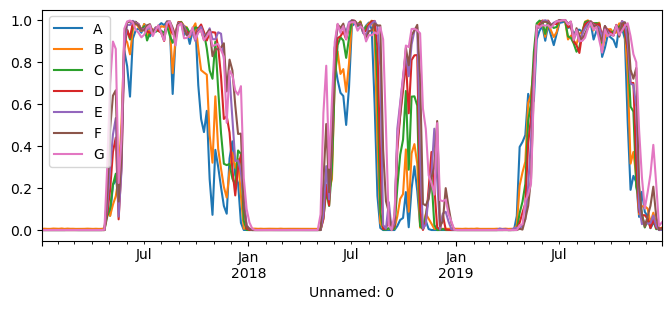

In [5]:
sea_ice_concentrations.plot(figsize=(8, 3));

In [6]:
sea_ice_drift = pd.read_csv(folder + "daily_sea_ice_drift.csv")
sea_ice_drift = clean_csv(sea_ice_drift)
sea_ice_drift.head()

,A,B,C,D,E,F,G
Unnamed: 0,,,,,,,
2017-01-03,0.006768-0.003681j,0.007022-0.005048j,0.008716-0.003232j,0.007812-0.003471j,-0.003815+0.009108j,0.004852-0.003987j,0.0+0.0j
2017-01-08,-0.037756+0.007992j,-0.009905+0.000551j,0.000000+0.000000j,0.000000+0.000000j,0.000000+0.000000j,0.000000+0.000000j,0.0+0.0j
2017-01-13,0.001824-0.001888j,0.000000+0.000000j,0.000000+0.000000j,0.000000+0.000000j,0.000000+0.000000j,0.000000+0.000000j,0.0+0.0j
2017-01-18,-0.004860+0.004333j,0.000000+0.000000j,0.000000+0.000000j,0.000000+0.000000j,0.000000+0.000000j,0.000000+0.000000j,0.0+0.0j
2017-01-23,0.000000+0.000000j,0.000000+0.000000j,0.000000+0.000000j,0.000000+0.000000j,0.000000+0.000000j,0.000000+0.000000j,0.0+0.0j


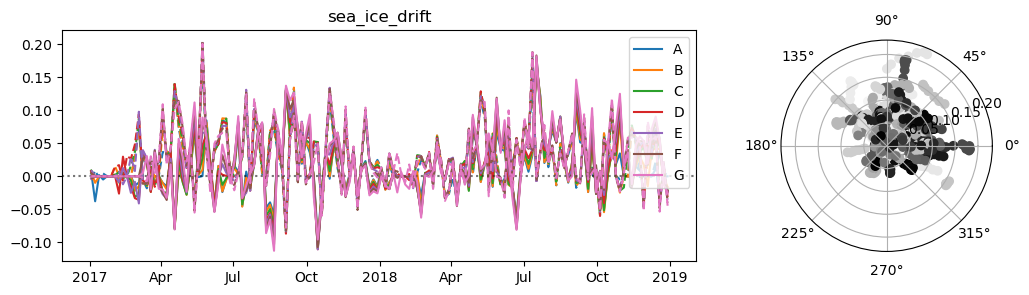

In [7]:
# fig,ax=plt.subplots(2,figsize=(10,3), subplot_kw=dict(projection=[None,'polar']))
fig, ax = setup_two_subplots(figsize=(12, 3))
plot_complex_df(sea_ice_drift, ax, colors, title="sea_ice_drift")

In [8]:
sea_surface_velocity_2017 = pd.read_csv(folder + "2017_5days_surface_velocity.csv")
sea_surface_velocity_2017 = clean_csv(sea_surface_velocity_2017)
sea_surface_velocity_2018 = pd.read_csv(folder + "2018_5days_surface_velocity.csv")
sea_surface_velocity_2018 = clean_csv(sea_surface_velocity_2018)
sea_surface_velocity = pd.concat(
    [sea_surface_velocity_2017, sea_surface_velocity_2018], axis="index"
)
sea_surface_velocity.index = [
    i.replace(hour=0, minute=0, second=0) for i in sea_surface_velocity.index
]
sea_surface_velocity.head()

,A,B,C,D,E,F,G
2017-01-03,0.015512-0.009334j,0.064841+0.033466j,0.057774+0.037763j,0.000269-0.012700j,-0.037029-0.044244j,-0.027685+0.010991j,0.024857+0.045718j
2017-01-08,-0.004051-0.012684j,0.034457+0.021706j,0.031036+0.025867j,-0.036308-0.039356j,-0.078557-0.069577j,-0.050566-0.017107j,0.024563+0.017522j
2017-01-13,-0.047259+0.043831j,0.017558+0.057752j,0.019715+0.063209j,-0.058447-0.019897j,-0.087549-0.040512j,-0.040678+0.042420j,0.005823+0.048975j
2017-01-18,-0.038571+0.015891j,-0.012885+0.035598j,-0.012885+0.046472j,-0.082503-0.048342j,-0.099453-0.065824j,-0.028406+0.026382j,-0.014763+0.006539j
2017-01-23,0.006799-0.012869j,0.026756+0.017391j,0.023158+0.036226j,-0.045845-0.054417j,-0.059670-0.063282j,0.026865+0.050546j,0.009712+0.023987j


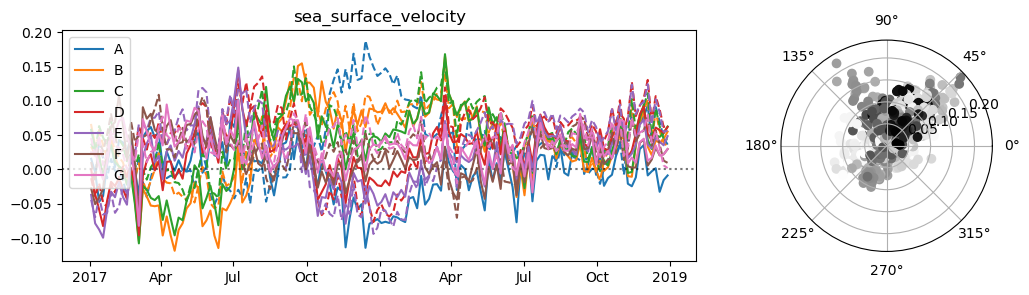

In [9]:
fig, ax = setup_two_subplots(figsize=(12, 3))
plot_complex_df(sea_surface_velocity, ax, colors, "sea_surface_velocity")

In [10]:
wind = pd.read_csv(folder + "daily_wind.csv")
wind = clean_csv(wind)
wind.head()

,A,B,C,D,E,F,G
Unnamed: 0,,,,,,,
2017-01-03,-3.230470-2.944423j,-3.262758-3.096254j,-3.108730-2.904774j,-3.006020-2.814638j,-3.193178-2.767506j,-3.461684-2.866444j,-3.415187-2.643910j
2017-01-08,-2.486272+2.175958j,-3.203606+1.696661j,-3.942143+1.021991j,-4.803789-0.014130j,-5.006621-0.660309j,-5.187627-1.120905j,-4.979277-2.087262j
2017-01-13,1.312288+5.400914j,0.946248+4.316258j,0.626472+3.254173j,0.464461+2.561961j,0.402412+2.082921j,0.326143+1.336082j,0.422737+0.933507j
2017-01-18,1.367303+4.961169j,1.122919+5.103699j,0.821979+5.293237j,0.121454+5.412000j,-0.275226+5.431348j,-1.451495+5.225818j,-2.000714+5.101416j
2017-01-23,-0.629607-0.761484j,-0.994109-0.728574j,-1.095744-0.474435j,-1.456389-0.380185j,-1.529863-0.004660j,-1.415288+0.737820j,-1.441264+1.147964j


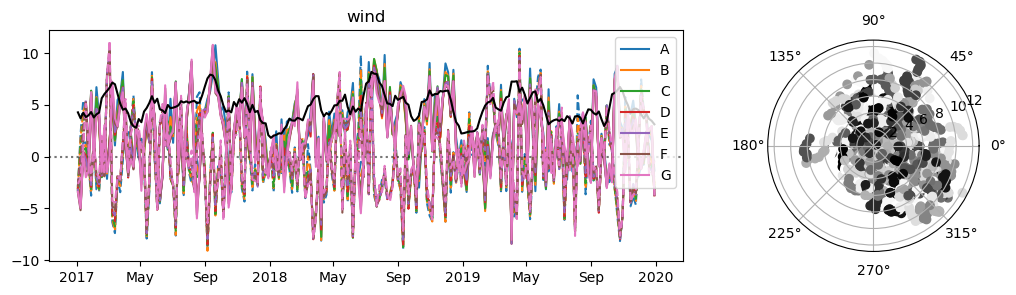

In [11]:
fig, ax = setup_two_subplots(figsize=(12, 3))
plot_complex_df(wind, ax, colors, "wind")
window = "30D"
ax[0].plot(
    wind.index,
    wind.abs().mean(axis="columns").rolling(window=window, center=True).mean(),
    color="black",
)

## Check time index

In [12]:
for df in [sea_ice_concentrations, sea_ice_drift, sea_surface_velocity]:
    print(df.index.identical(wind.index))

True
False
False


## Momentum transfer
Equations are taken from Ralphs PhD thesis. See also [Losch et al., 2012](https://doi.org/10.1016/j.ocemod.2011.10.002)
\begin{equation}
    \vec{\tau} = A \vec{\tau}_\text{io} + (1-A) \vec{\tau}_\text{ao}
\end{equation}
with atmosphere--ocean interaction $\vec{\tau}_\text{ao}$
\begin{equation}
|\vec{\tau}_\text{ao}| = \rho_\text{a} c_\text{D} |u_{10}|^2 \qquad \text{with}\: \rho_\text{a} \approx 1.3\,\text{kg/m}^3,\:c_\text{D} = 1\times10^{-3}
\end{equation}
and ice-ocean interaction $\vec{\tau}_\text{io}$
\begin{equation}
|\vec{\tau}_\text{io}| = \rho_\text{w} c_\text{D, io} |(\vec{u}_\text{o}-\vec{u}_\text{i})|^2 \qquad \text{with}\: \rho_\text{w} \approx 1000\,\text{kg/m}^3,\:c_\text{D} = 3\times10^{-3}
\end{equation}
If the ice velocity $\vec{u}_\text{i}$ is unknow, we can parameterize $|\vec{\tau}_\text{io}|$ from the ice hardness $P$ ([Hibler, 1979](https://doi.org/10.1175/1520-0485(1979)009<0815:ADTSIM>2.0.CO;2))
\begin{equation}
P \propto e^{-20(1-A)} 
\end{equation}

In [13]:
air_density = 1.3
air_drag_coefficient = 1e-3
momentum_transfer_atmos_ocean = air_density * air_drag_coefficient * wind.abs() * wind

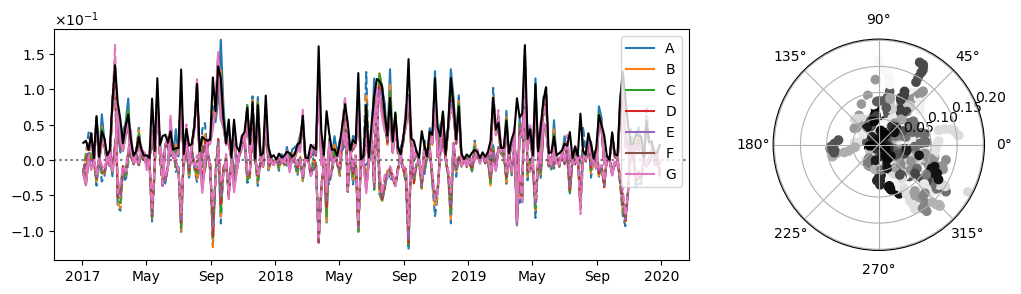

In [14]:
fig, ax = setup_two_subplots(figsize=(12, 3))
plot_complex_df(momentum_transfer_atmos_ocean, ax, colors)
ax[0].ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useMathText=True)
ax[0].plot(
    momentum_transfer_atmos_ocean.index,
    momentum_transfer_atmos_ocean.abs().mean(axis="columns"),
    color="black",
)

In [15]:
water_density = 1000
ice_drag_coefficient = 5.5e-3
momentum_transfer_ice_ocean = (
    water_density
    * ice_drag_coefficient
    * (sea_surface_velocity - sea_ice_drift).abs()
    * (sea_surface_velocity - sea_ice_drift)
)

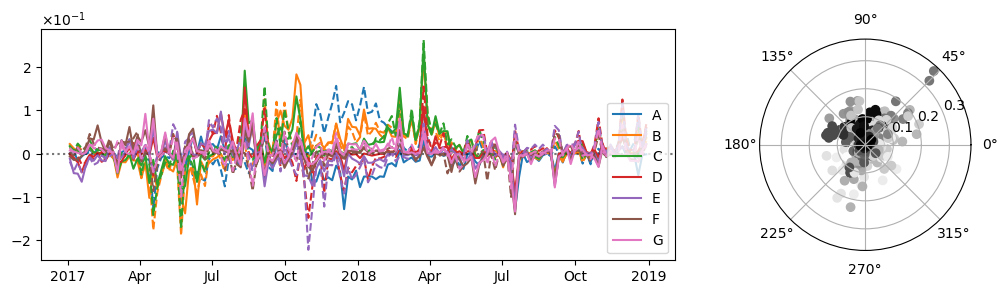

In [16]:
fig, ax = setup_two_subplots(figsize=(12, 3))
ax[0].ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useMathText=True)
plot_complex_df(momentum_transfer_ice_ocean, ax, colors)

In [17]:
momentum_transfer = (sea_ice_concentrations * momentum_transfer_ice_ocean) + (
    (1 - sea_ice_concentrations) * momentum_transfer_atmos_ocean
)

In [18]:
momentum_transfer.to_csv("../../derived_data/daily_momentum_transfer.csv", na_rep="NaN")
momentum_transfer_ice_ocean.to_csv(
    "../../derived_data/daily_momentum_transfer_ice_ocean.csv", na_rep="NaN"
)
momentum_transfer_atmos_ocean.to_csv(
    "../../derived_data/daily_momentum_transfer_atmos_ocean.csv", na_rep="NaN"
)

In [19]:
# cut of trailing empty months
momentum_transfer = momentum_transfer.dropna(axis="index")
momentum_transfer.head()

,A,B,C,D,E,F,G
2017-01-03,-0.018353-0.016728j,-0.018844-0.017918j,-0.017194-0.016066j,-0.016093-0.015068j,-0.017541-0.015203j,-0.020226-0.016748j,-0.019175-0.014845j
2017-01-08,-0.010679+0.009346j,-0.014927+0.007982j,-0.020871+0.005411j,-0.029999-0.000088j,-0.032868-0.004335j,-0.035792-0.007734j,-0.034948-0.014650j
2017-01-13,0.009482+0.039024j,0.005438+0.024764j,0.002699+0.014019j,0.001572+0.008672j,0.001110+0.005744j,0.000583+0.002389j,0.000563+0.001244j
2017-01-18,0.009147+0.033189j,0.007572+0.034521j,0.005724+0.036860j,0.000855+0.038086j,-0.001946+0.038399j,-0.010234+0.036846j,-0.014252+0.036341j
2017-01-23,-0.000809-0.000978j,-0.001549-0.001138j,-0.001701-0.000736j,-0.002850-0.000744j,-0.003043-0.000009j,-0.002937+0.001531j,-0.003452+0.002750j


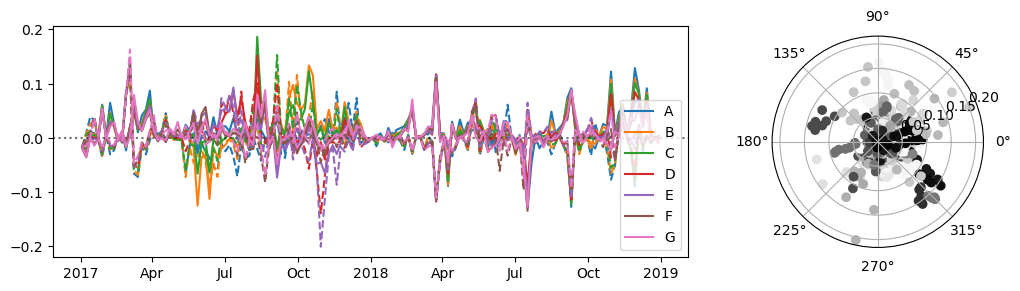

In [20]:
fig, ax = setup_two_subplots(figsize=(12, 3))
plot_complex_df(momentum_transfer, ax, colors)

In [21]:
# dot product of 2 vectors, expressed as complex numbers
energy_transfer = (sea_surface_velocity * np.conjugate(momentum_transfer)).apply(np.real)

In [22]:
# energy_transfer = energy_transfer.dropna(axis="index")
energy_transfer

,A,B,C,D,E,F,G
2017-01-03,-0.000129,-0.001821,-0.001600,0.000187,0.001322,0.000376,-0.001155
2017-01-08,-0.000075,-0.000341,-0.000508,0.001093,0.002884,0.001942,-0.001115
2017-01-13,0.001262,0.001526,0.000939,-0.000264,-0.000330,0.000078,0.000064
2017-01-18,0.000175,0.001131,0.001639,-0.001912,-0.002334,0.001263,0.000448
2017-01-23,0.000007,-0.000061,-0.000066,0.000171,0.000182,-0.000002,0.000032
...,...,...,...,...,...,...,...
2018-12-09,-0.001049,-0.000259,-0.000075,0.000074,-0.000017,0.000043,0.000108
2018-12-14,0.000587,0.003845,0.004247,0.004526,0.003092,0.001566,0.001795
2018-12-19,-0.000903,-0.000329,-0.000321,-0.000478,-0.000267,-0.000108,-0.000098
2018-12-24,-0.000034,-0.000012,-0.000002,-0.000007,0.000003,-0.000023,-0.000037


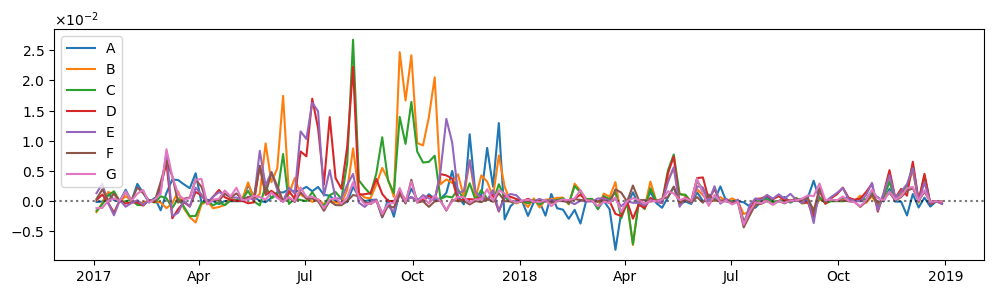

In [23]:
fig, ax = plt.subplots(1, figsize=(12, 3))
ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useMathText=True)
plot_complex_df(energy_transfer, ax, colors)

In [24]:
f"mean energy transfer = {energy_transfer.mean(axis=None):.1e}"

'mean energy transfer = 9.8e-04'

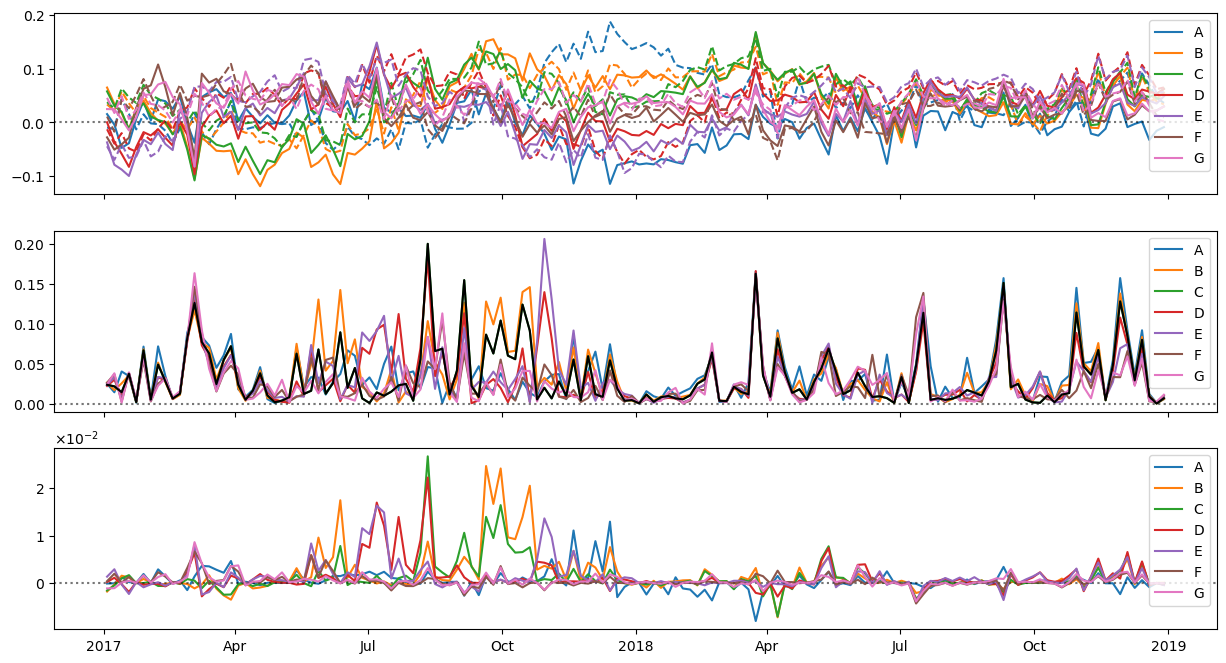

In [25]:
fig, ax = plt.subplots(nrows=3, sharex=True, figsize=(15, 8))
for axis in ax:
    axis.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2), useMathText=True)
plot_complex_df(sea_surface_velocity, ax[0], colors)
plot_complex_df(momentum_transfer.abs(), ax[1], colors)
plot_complex_df(energy_transfer, ax[2], colors)
ax[1].plot(momentum_transfer.index, momentum_transfer["C"].abs(), "k")

In [26]:
energy_transfer.to_csv("../../derived_data/daily_energy_transfer.csv", na_rep="NaN")